In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df_original = pd.read_csv("loan_data.csv")

df = df_original.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five records:")
display(df.head())

Number of rows: 45000
Number of columns: 14

First five records:


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [6]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_lo

In [7]:
print("\nStatistical Summary:")
display(df.describe(include='all').T)


Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_age,45000.0,NaN,NaN,NaN,27.764178,6.045108,20.0,24.0,26.0,30.0,144.0
person_gender,45000,2,male,24841,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_education,45000,5,Bachelor,13399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_income,45000.0,NaN,NaN,NaN,80319.053222,80422.498632,8000.0,47204.0,67048.0,95789.25,7200766.0
person_emp_exp,45000.0,NaN,NaN,NaN,5.410333,6.063532,0.0,1.0,4.0,8.0,125.0
person_home_ownership,45000,4,RENT,23443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,45000.0,NaN,NaN,NaN,9583.157556,6314.886691,500.0,5000.0,8000.0,12237.25,35000.0
loan_intent,45000,6,EDUCATION,9153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_int_rate,45000.0,NaN,NaN,NaN,11.006606,2.978808,5.42,8.59,11.01,12.99,20.0
loan_percent_income,45000.0,NaN,NaN,NaN,0.139725,0.087212,0.0,0.07,0.12,0.19,0.66


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Variable Distribution:")
print(df['loan_status'].value_counts())

print("\nTarget Variable Percentage:")
print(df['loan_status'].value_counts(normalize=True) * 100)

Missing Values:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Duplicate Records:
0

Target Variable Distribution:
0    35000
1    10000
Name: loan_status, dtype: int64

Target Variable Percentage:
0    77.777778
1    22.222222
Name: loan_status, dtype: float64


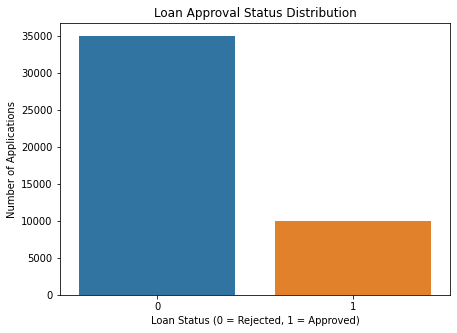

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='loan_status')

plt.title('Loan Approval Status Distribution')
plt.xlabel('Loan Status (0 = Rejected, 1 = Approved)')
plt.ylabel('Number of Applications')

plt.show()

In [10]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

# Remove target variable from numerical input features
numerical_columns.remove('loan_status')

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Features:
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Categorical Features:
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


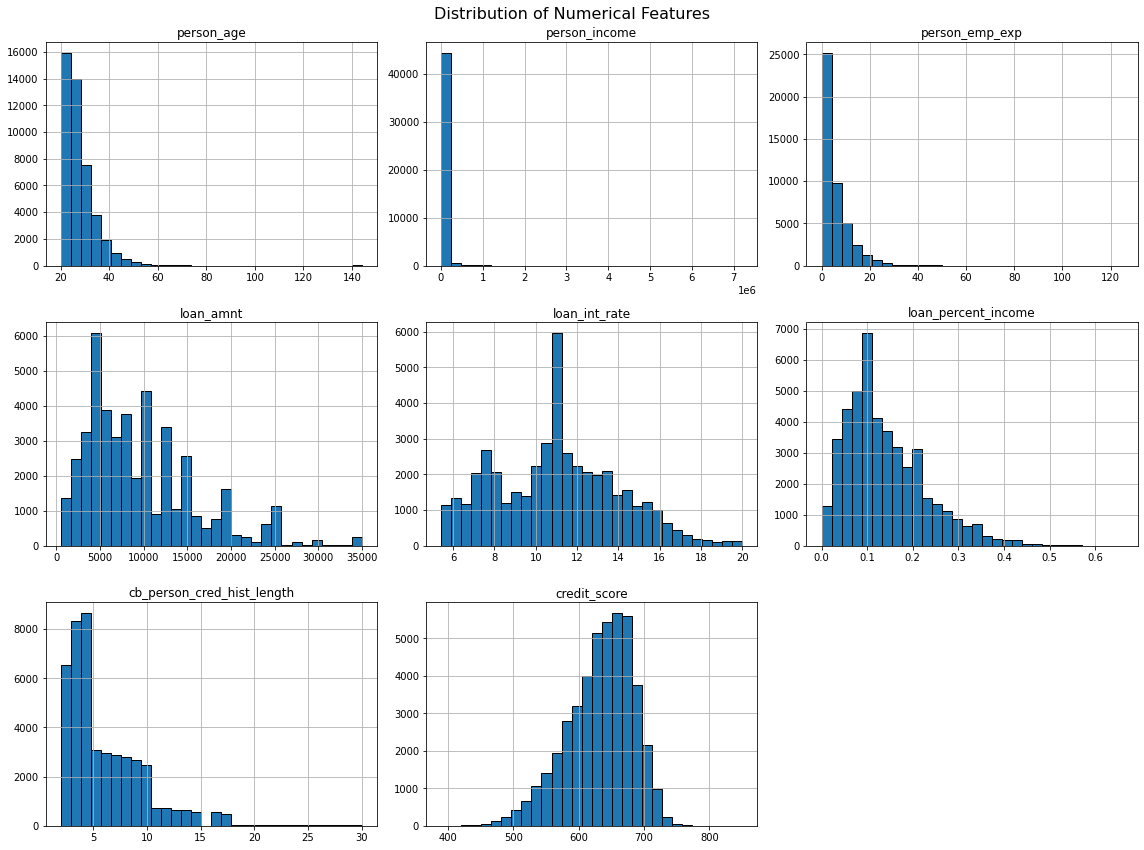

In [11]:
# Plot distributions of numerical features

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

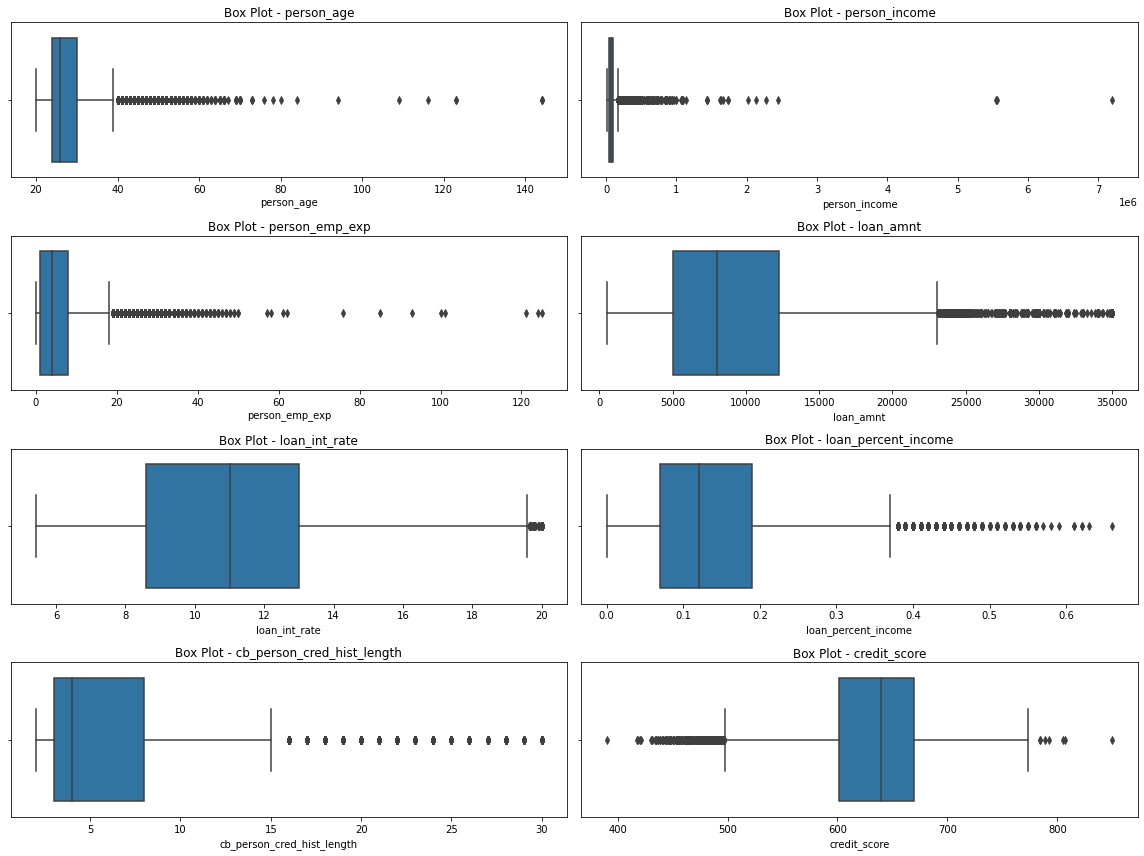

In [12]:
# Box plots for numerical features

plt.figure(figsize=(16, 12))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(4, 2, i)

    sns.boxplot(x=df[column])

    plt.title(f"Box Plot - {column}")

plt.tight_layout()
plt.show()

In [13]:
# Calculate outliers using IQR method

outlier_results = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_results.append({
        'Feature': column,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier Percentage': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,person_age,15.000,39.000,2188,4.86
1,person_income,-25673.875,168667.125,2218,4.93
2,person_emp_exp,-9.500,18.500,1724,3.83
3,loan_amnt,-5855.875,23093.125,2348,5.22
4,loan_int_rate,1.990,19.590,124,0.28
5,loan_percent_income,-0.110,0.370,744,1.65
6,cb_person_cred_hist_length,-4.500,15.500,1366,3.04
7,credit_score,497.500,773.500,467,1.04


In [14]:
# Analyse categorical features

for column in categorical_columns:

    print("\nFeature:", column)

    print(df[column].value_counts())

    print("\nPercentage Distribution:")

    print(
        (df[column].value_counts(normalize=True) * 100)
        .round(2)
    )

    print("-" * 50)


Feature: person_gender
male      24841
female    20159
Name: person_gender, dtype: int64

Percentage Distribution:
male      55.2
female    44.8
Name: person_gender, dtype: float64
--------------------------------------------------

Feature: person_education
Bachelor       13399
Associate      12028
High School    11972
Master          6980
Doctorate        621
Name: person_education, dtype: int64

Percentage Distribution:
Bachelor       29.78
Associate      26.73
High School    26.60
Master         15.51
Doctorate       1.38
Name: person_education, dtype: float64
--------------------------------------------------

Feature: person_home_ownership
RENT        23443
MORTGAGE    18489
OWN          2951
OTHER         117
Name: person_home_ownership, dtype: int64

Percentage Distribution:
RENT        52.10
MORTGAGE    41.09
OWN          6.56
OTHER        0.26
Name: person_home_ownership, dtype: float64
--------------------------------------------------

Feature: loan_intent
EDUCATION       

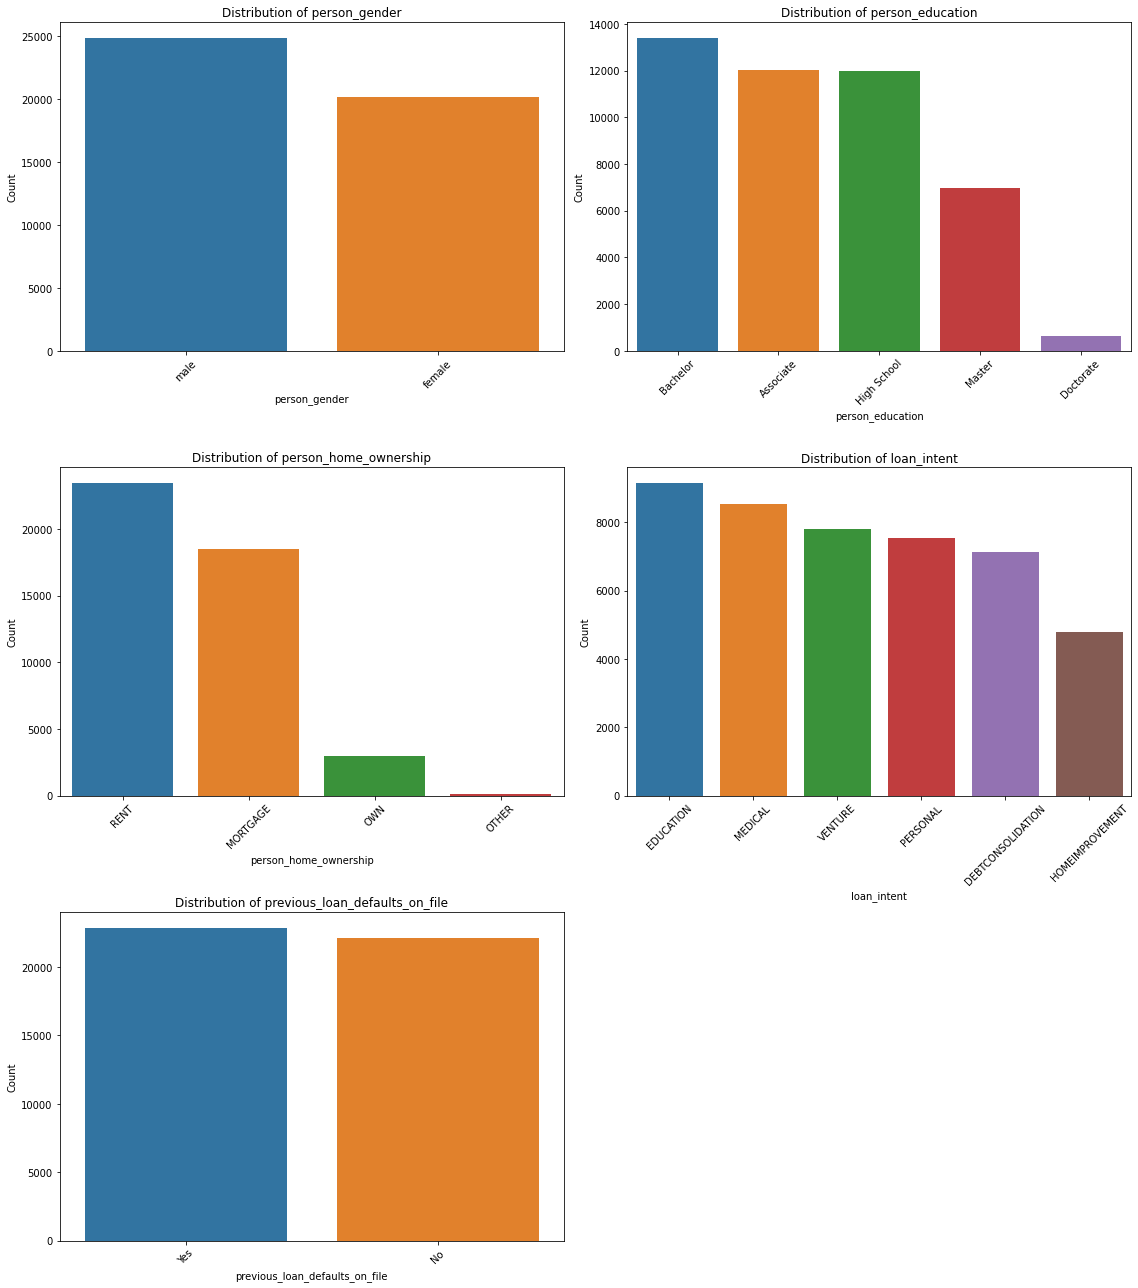

In [15]:
# Visualize categorical feature distributions

plt.figure(figsize=(16, 18))

for i, column in enumerate(categorical_columns, 1):

    plt.subplot(3, 2, i)

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45)

    plt.xlabel(column)
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [16]:
# Investigate unusual records

print("Applicants older than 100:")
print(
    df[df['person_age'] > 100][
        ['person_age', 'person_emp_exp', 'loan_status']
    ]
)

print("\nApplicants with employment experience greater than age:")
print(
    df[df['person_emp_exp'] > df['person_age']][
        ['person_age', 'person_emp_exp', 'loan_status']
    ]
)

print("\nApplicants with age greater than 100 - Count:")
print((df['person_age'] > 100).sum())

print("\nExperience greater than age - Count:")
print((df['person_emp_exp'] > df['person_age']).sum())

Applicants older than 100:
       person_age  person_emp_exp  loan_status
81          144.0             125            0
183         144.0             121            0
575         123.0             101            0
747         123.0             100            0
32297       144.0             124            0
37930       116.0              93            0
38113       109.0              85            0

Applicants with employment experience greater than age:
Empty DataFrame
Columns: [person_age, person_emp_exp, loan_status]
Index: []

Applicants with age greater than 100 - Count:
7

Experience greater than age - Count:
0


In [17]:
# Calculate correlation between numerical features

correlation_matrix = df[numerical_columns + ['loan_status']].corr()

# Display correlation matrix

display(correlation_matrix.round(2))

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
person_age,1.00,0.19,0.95,0.05,0.01,-0.04,0.86,0.18,-0.02
person_income,0.19,1.00,0.19,0.24,0.00,-0.23,0.12,0.04,-0.14
person_emp_exp,0.95,0.19,1.00,0.04,0.02,-0.04,0.82,0.19,-0.02
loan_amnt,0.05,0.24,0.04,1.00,0.15,0.59,0.04,0.01,0.11
loan_int_rate,0.01,0.00,0.02,0.15,1.00,0.13,0.02,0.01,0.33
loan_percent_income,-0.04,-0.23,-0.04,0.59,0.13,1.00,-0.03,-0.01,0.38
cb_person_cred_hist_length,0.86,0.12,0.82,0.04,0.02,-0.03,1.00,0.16,-0.01
credit_score,0.18,0.04,0.19,0.01,0.01,-0.01,0.16,1.00,-0.01
loan_status,-0.02,-0.14,-0.02,0.11,0.33,0.38,-0.01,-0.01,1.00


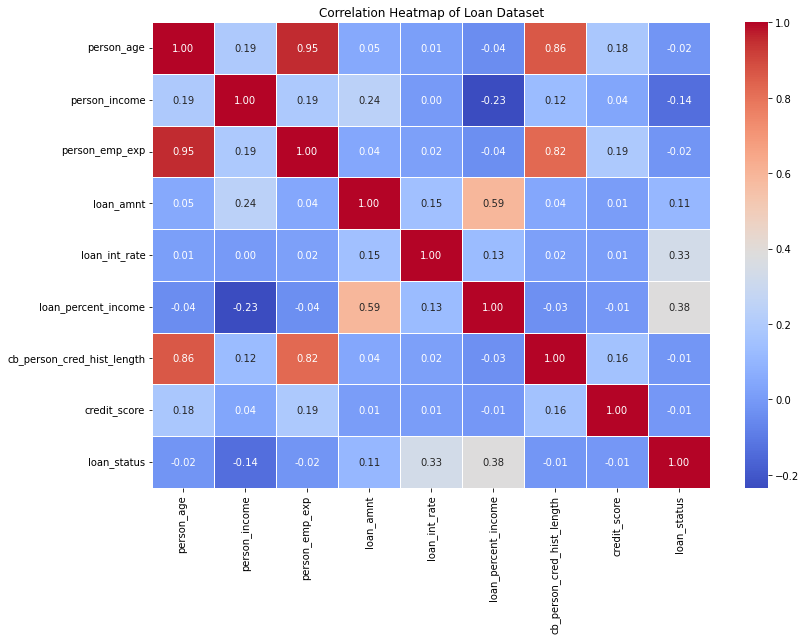

In [18]:
# Correlation heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Loan Dataset")

plt.tight_layout()
plt.show()

In [19]:
# Correlation with target variable

target_correlation = (
    correlation_matrix['loan_status']
    .drop('loan_status')
    .sort_values(ascending=False)
)

print("Correlation with Loan Status:")

display(target_correlation.to_frame())

Correlation with Loan Status:


,loan_status
loan_percent_income,0.384880
loan_int_rate,0.332005
loan_amnt,0.107714
credit_score,-0.007647
cb_person_cred_hist_length,-0.014851
person_emp_exp,-0.020481
person_age,-0.021476
person_income,-0.135808


In [20]:
# Analyse categorical features against loan status

for column in categorical_columns:

    print("\nLoan Approval Analysis:", column)

    approval_table = pd.crosstab(
        df[column],
        df['loan_status'],
        normalize='index'
    ) * 100

    display(approval_table.round(2))


Loan Approval Analysis: person_gender


loan_status,0,1
person_gender,,
female,77.75,22.25
male,77.80,22.20



Loan Approval Analysis: person_education


loan_status,0,1
person_education,,
Associate,77.97,22.03
Bachelor,77.48,22.52
Doctorate,77.13,22.87
High School,77.69,22.31
Master,78.24,21.76



Loan Approval Analysis: person_home_ownership


loan_status,0,1
person_home_ownership,,
MORTGAGE,88.40,11.60
OTHER,66.67,33.33
OWN,92.48,7.52
RENT,67.60,32.40



Loan Approval Analysis: loan_intent


loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,69.73,30.27
EDUCATION,83.04,16.96
HOMEIMPROVEMENT,73.70,26.30
MEDICAL,72.18,27.82
PERSONAL,79.86,20.14
VENTURE,85.57,14.43



Loan Approval Analysis: previous_loan_defaults_on_file


loan_status,0,1
previous_loan_defaults_on_file,,
No,54.84,45.16
Yes,100.00,0.00


In [21]:
# Compare numerical features based on loan status

for column in numerical_columns:

    print("\nFeature:", column)

    display(
        df.groupby('loan_status')[column]
        .agg(['mean', 'median', 'std', 'min', 'max'])
        .round(2)
    )


Feature: person_age


,mean,median,std,min,max
loan_status,,,,,
0,27.83,26.0,6.07,20.0,144.0
1,27.52,26.0,5.94,20.0,70.0



Feature: person_income


,mean,median,std,min,max
loan_status,,,,,
0,86157.04,72928.0,87035.24,9595.0,7200766.0
1,59886.10,50629.0,45338.32,8000.0,845636.0



Feature: person_emp_exp


,mean,median,std,min,max
loan_status,,,,,
0,5.48,4.0,6.10,0,125
1,5.18,3.0,5.91,0,47


... (6 outputs left out)


Feature: cb_person_cred_hist_length


,mean,median,std,min,max
loan_status,,,,,
0,5.90,4.0,3.87,2.0,30.0
1,5.76,4.0,3.90,2.0,30.0



Feature: credit_score


,mean,median,std,min,max
loan_status,,,,,
0,632.81,640.0,50.48,390,850
1,631.89,639.0,50.29,431,767


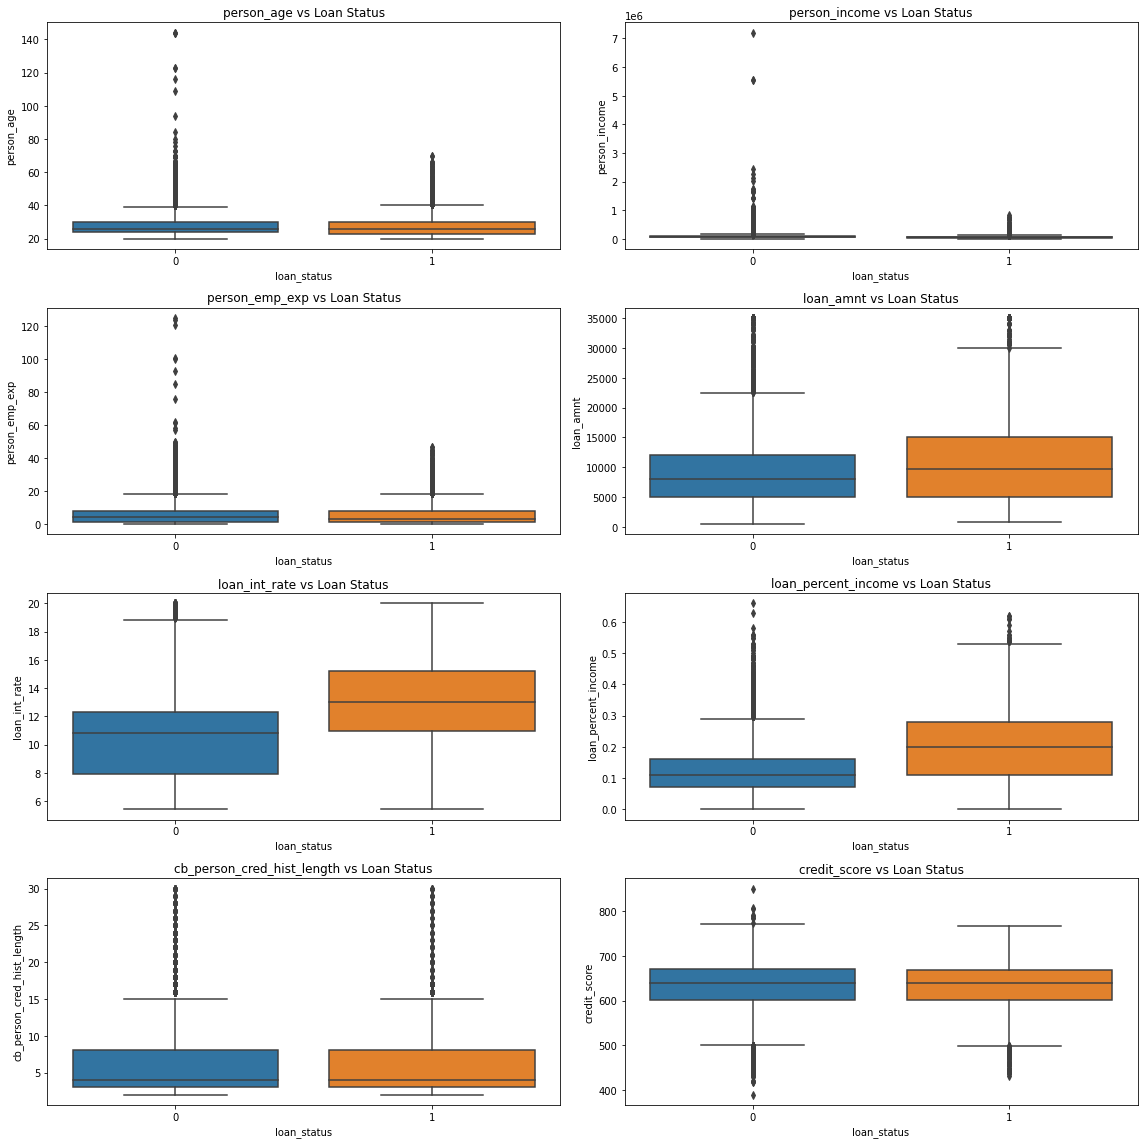

In [22]:
# Compare numerical features across loan status

plt.figure(figsize=(16, 16))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(4, 2, i)

    sns.boxplot(
        data=df,
        x='loan_status',
        y=column
    )

    plt.title(f'{column} vs Loan Status')

plt.tight_layout()
plt.show()

In [23]:
# Examine relationship between previous defaults and loan status

default_analysis = pd.crosstab(
    df['previous_loan_defaults_on_file'],
    df['loan_status']
)

print("Previous Defaults vs Loan Status:")

display(default_analysis)

print("\nApproval percentage by previous defaults:")

display(
    pd.crosstab(
        df['previous_loan_defaults_on_file'],
        df['loan_status'],
        normalize='index'
    ).mul(100).round(2)
)

Previous Defaults vs Loan Status:


loan_status,0,1
previous_loan_defaults_on_file,,
No,12142,10000
Yes,22858,0



Approval percentage by previous defaults:


loan_status,0,1
previous_loan_defaults_on_file,,
No,54.84,45.16
Yes,100.00,0.00


In [24]:
# Compare interest rates by loan status

display(
    df.groupby('loan_status')['loan_int_rate']
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
0,35000.0,10.48,2.73,5.42,7.90,10.85,12.29,20.0
1,10000.0,12.86,3.07,5.42,10.99,12.98,15.23,20.0


In [25]:
# Create a separate working dataset

df_clean = df.copy()

# Identify unrealistic age records
invalid_age = df_clean['person_age'] > 100

print("Records with age above 100:",
      invalid_age.sum())

# Remove unrealistic age records
df_clean = df_clean[~invalid_age].copy()

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("\nDataset after cleaning:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nAge statistics:")
print(df_clean['person_age'].describe())

Records with age above 100: 7

Dataset after cleaning:
Rows: 44993
Columns: 14

Age statistics:
count    44993.000000
mean        27.748428
std          5.909737
min         20.000000
25%         24.000000
50%         26.000000
75%         30.000000
max         94.000000
Name: person_age, dtype: float64


In [26]:
# Save cleaned dataset

df_clean.to_csv(
    "loan_data_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
print("Missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nTarget distribution:")
print(df_clean['loan_status'].value_counts())

print("\nTarget percentage:")
print(
    df_clean['loan_status']
    .value_counts(normalize=True) * 100
)

Missing values:
0

Duplicate records:
0

Target distribution:
0    34993
1    10000
Name: loan_status, dtype: int64

Target percentage:
0    77.77432
1    22.22568
Name: loan_status, dtype: float64


In [28]:
# Separate input features and target variable

X = df_clean.drop('loan_status', axis=1)

y = df_clean['loan_status']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

Input Features Shape: (44993, 13)
Target Variable Shape: (44993,)

Input Features:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']

Target Classes:
[1 0]


In [29]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Data Shape: (35994, 13)
Testing Data Shape: (8999, 13)

Training Target Distribution:
0    77.774073
1    22.225927
Name: loan_status, dtype: float64

Testing Target Distribution:
0    77.775308
1    22.224692
Name: loan_status, dtype: float64


In [30]:
# Identify feature types from training data

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Categorical Features:
['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing

numerical_transformer = StandardScaler()

# Categorical preprocessing

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [32]:
# Import machine learning classification algorithms

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

# Import pipeline

from sklearn.pipeline import Pipeline

print("All five classification algorithms imported successfully!")

All five classification algorithms imported successfully!


In [33]:
# Create machine learning models

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Gaussian Naive Bayes': GaussianNB(),

    'Support Vector Machine': SVC(
        kernel='rbf',
        random_state=42
    )

}

print("Five machine learning models created successfully!")

Five machine learning models created successfully!


In [34]:
# Create pipelines for all five models

model_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )

    model_pipelines[name] = pipeline

print("All model pipelines created successfully!")

print("\nAvailable Models:")

for name in model_pipelines:
    print(name)

All model pipelines created successfully!

Available Models:
Logistic Regression
Decision Tree
K-Nearest Neighbors
Gaussian Naive Bayes
Support Vector Machine


In [35]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [36]:
# Train Logistic Regression

import time

start_time = time.time()

lr_model = model_pipelines['Logistic Regression']

lr_model.fit(X_train, y_train)

end_time = time.time()

lr_training_time = end_time - start_time

print("Logistic Regression trained successfully!")

print("Training Time:", round(lr_training_time, 2), "seconds")

Logistic Regression trained successfully!
Training Time: 1.14 seconds


In [37]:
# Predict loan approval on testing data

y_pred_lr = lr_model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_lr[:20])

Predictions completed successfully!

First 20 Actual Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]

First 20 Predicted Values:
[1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0]


In [38]:
# Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test, y_pred_lr, zero_division=0
)

lr_recall = recall_score(
    y_test, y_pred_lr, zero_division=0
)

lr_f1 = f1_score(
    y_test, y_pred_lr, zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_test,
    lr_model.predict_proba(X_test)[:, 1]
)

print("LOGISTIC REGRESSION - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION - PERFORMANCE
----------------------------------
Accuracy : 0.8949
Precision: 0.7722
Recall   : 0.7475
F1 Score : 0.7597
ROC-AUC  : 0.9523

Confusion Matrix:
[[6558  441]
 [ 505 1495]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      6999
           1       0.77      0.75      0.76      2000

    accuracy                           0.89      8999
   macro avg       0.85      0.84      0.85      8999
weighted avg       0.89      0.89      0.89      8999



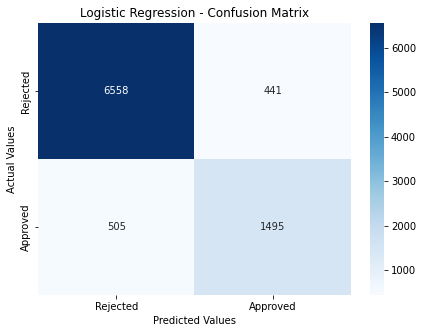

In [39]:
# Plot confusion matrix

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [40]:
# Train Decision Tree Classifier

start_time = time.time()

dt_model = model_pipelines['Decision Tree']

dt_model.fit(X_train, y_train)

end_time = time.time()

dt_training_time = end_time - start_time

print("Decision Tree trained successfully!")

print("Training Time:",
      round(dt_training_time, 2), "seconds")

Decision Tree trained successfully!
Training Time: 0.63 seconds


In [41]:
# Predict using Decision Tree

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions completed!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_dt[:20])

Decision Tree predictions completed!

First 20 Actual Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]

First 20 Predicted Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]


In [42]:
# Evaluate Decision Tree Classifier

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, zero_division=0
)

dt_recall = recall_score(
    y_test, y_pred_dt, zero_division=0
)

dt_f1 = f1_score(
    y_test, y_pred_dt, zero_division=0
)

dt_roc_auc = roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test)[:, 1]
)

print("DECISION TREE - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("ROC-AUC  :", round(dt_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

DECISION TREE - PERFORMANCE
----------------------------------
Accuracy : 0.894
Precision: 0.7519
Recall   : 0.7805
F1 Score : 0.7659
ROC-AUC  : 0.8535

Confusion Matrix:
[[6484  515]
 [ 439 1561]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      6999
           1       0.75      0.78      0.77      2000

    accuracy                           0.89      8999
   macro avg       0.84      0.85      0.85      8999
weighted avg       0.90      0.89      0.89      8999



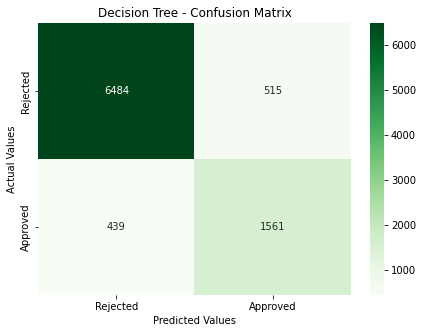

In [43]:
# Plot Decision Tree confusion matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [44]:
# Train K-Nearest Neighbors Classifier

start_time = time.time()

knn_model = model_pipelines['K-Nearest Neighbors']

knn_model.fit(X_train, y_train)

end_time = time.time()

knn_training_time = end_time - start_time

print("KNN trained successfully!")

print("Training Time:",
      round(knn_training_time, 2), "seconds")

KNN trained successfully!
Training Time: 0.14 seconds


In [45]:
# Predict using KNN

y_pred_knn = knn_model.predict(X_test)

print("KNN predictions completed successfully!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_knn[:20])

KNN predictions completed successfully!

First 20 Actual Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]

First 20 Predicted Values:
[1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0]


In [46]:
# Evaluate KNN Classifier

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, zero_division=0
)

knn_recall = recall_score(
    y_test, y_pred_knn, zero_division=0
)

knn_f1 = f1_score(
    y_test, y_pred_knn, zero_division=0
)

knn_roc_auc = roc_auc_score(
    y_test,
    knn_model.predict_proba(X_test)[:, 1]
)

print("KNN - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("ROC-AUC  :", round(knn_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN - PERFORMANCE
----------------------------------
Accuracy : 0.8959
Precision: 0.7974
Recall   : 0.7125
F1 Score : 0.7526
ROC-AUC  : 0.9255

Confusion Matrix:
[[6637  362]
 [ 575 1425]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.95      0.93      6999
           1       0.80      0.71      0.75      2000

    accuracy                           0.90      8999
   macro avg       0.86      0.83      0.84      8999
weighted avg       0.89      0.90      0.89      8999



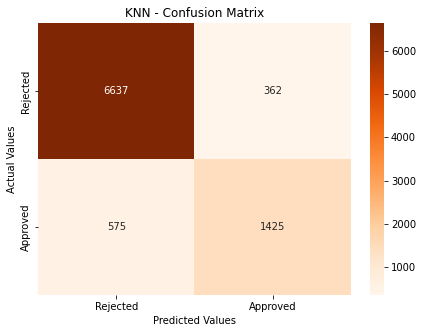

In [47]:
# Plot KNN confusion matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title('KNN - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [48]:
# Train Gaussian Naive Bayes Classifier

start_time = time.time()

nb_model = model_pipelines['Gaussian Naive Bayes']

nb_model.fit(X_train, y_train)

end_time = time.time()

nb_training_time = end_time - start_time

print("Gaussian Naive Bayes trained successfully!")

print("Training Time:",
      round(nb_training_time, 2), "seconds")

Gaussian Naive Bayes trained successfully!
Training Time: 0.18 seconds


In [49]:
# Predict using Gaussian Naive Bayes

y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes predictions completed successfully!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_nb[:20])

Naive Bayes predictions completed successfully!

First 20 Actual Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]

First 20 Predicted Values:
[1 0 0 0 0 1 1 1 1 0 0 0 1 0 1 1 1 0 0 0]


In [50]:
# Evaluate Gaussian Naive Bayes

nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test, y_pred_nb, zero_division=0
)

nb_recall = recall_score(
    y_test, y_pred_nb, zero_division=0
)

nb_f1 = f1_score(
    y_test, y_pred_nb, zero_division=0
)

nb_roc_auc = roc_auc_score(
    y_test,
    nb_model.predict_proba(X_test)[:, 1]
)

print("GAUSSIAN NAIVE BAYES - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("ROC-AUC  :", round(nb_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

GAUSSIAN NAIVE BAYES - PERFORMANCE
----------------------------------
Accuracy : 0.7327
Precision: 0.4539
Recall   : 0.998
F1 Score : 0.624
ROC-AUC  : 0.936

Confusion Matrix:
[[4598 2401]
 [   4 1996]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.66      0.79      6999
           1       0.45      1.00      0.62      2000

    accuracy                           0.73      8999
   macro avg       0.73      0.83      0.71      8999
weighted avg       0.88      0.73      0.76      8999



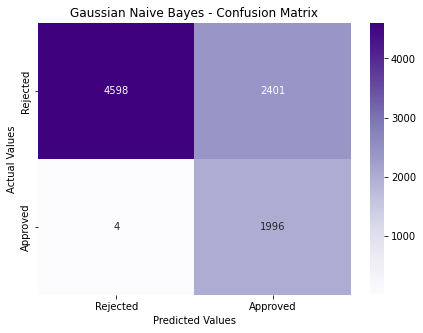

In [51]:
# Plot Gaussian Naive Bayes confusion matrix

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title('Gaussian Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [52]:
# Train Support Vector Machine Classifier

start_time = time.time()

svm_model = model_pipelines['Support Vector Machine']

svm_model.fit(X_train, y_train)

end_time = time.time()

svm_training_time = end_time - start_time

print("SVM trained successfully!")

print("Training Time:",
      round(svm_training_time, 2), "seconds")

SVM trained successfully!
Training Time: 51.15 seconds


In [53]:
# Predict using SVM

y_pred_svm = svm_model.predict(X_test)

print("SVM predictions completed successfully!")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred_svm[:20])

SVM predictions completed successfully!

First 20 Actual Values:
[0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]

First 20 Predicted Values:
[1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0]


In [54]:
# Evaluate Support Vector Machine

svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test, y_pred_svm, zero_division=0
)

svm_recall = recall_score(
    y_test, y_pred_svm, zero_division=0
)

svm_f1 = f1_score(
    y_test, y_pred_svm, zero_division=0
)

# Use decision_function instead of predict_proba

svm_roc_auc = roc_auc_score(
    y_test,
    svm_model.decision_function(X_test)
)

print("SUPPORT VECTOR MACHINE - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("ROC-AUC  :", round(svm_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SUPPORT VECTOR MACHINE - PERFORMANCE
----------------------------------
Accuracy : 0.9165
Precision: 0.8534
Recall   : 0.754
F1 Score : 0.8006
ROC-AUC  : 0.963

Confusion Matrix:
[[6740  259]
 [ 492 1508]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      6999
           1       0.85      0.75      0.80      2000

    accuracy                           0.92      8999
   macro avg       0.89      0.86      0.87      8999
weighted avg       0.91      0.92      0.91      8999



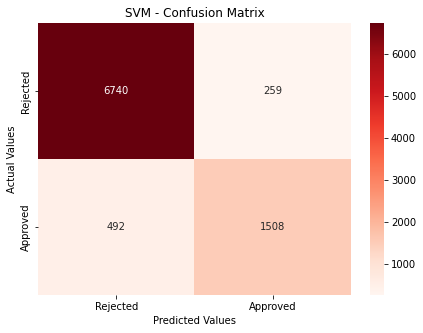

In [55]:
# Plot SVM confusion matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

plt.title('SVM - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [56]:
# Remove previous loan defaults feature

feature_to_remove = 'previous_loan_defaults_on_file'

X_train_reduced = X_train.drop(
    columns=[feature_to_remove]
)

X_test_reduced = X_test.drop(
    columns=[feature_to_remove]
)

print("Original training features:", X_train.shape[1])
print("Reduced training features:", X_train_reduced.shape[1])

print("\nRemaining features:")
print(X_train_reduced.columns.tolist())

Original training features: 13
Reduced training features: 12

Remaining features:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']


In [57]:
# Identify numerical and categorical features

numerical_features_reduced = [
    col for col in numerical_features
    if col in X_train_reduced.columns
]

categorical_features_reduced = [
    col for col in categorical_features
    if col in X_train_reduced.columns
]

# Create preprocessing pipeline

preprocessor_reduced = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_reduced),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features_reduced)
    ]
)

print("Reduced preprocessing pipeline created successfully!")

Reduced preprocessing pipeline created successfully!


In [58]:
# Create SVM without previous defaults feature

svm_reduced = Pipeline(
    steps=[
        ('preprocessor', preprocessor_reduced),
        ('classifier', SVC(
            kernel='rbf',
            random_state=42
        ))
    ]
)

start_time = time.time()

svm_reduced.fit(X_train_reduced, y_train)

end_time = time.time()

svm_reduced_training_time = end_time - start_time

print("Reduced SVM trained successfully!")

print("Training Time:",
      round(svm_reduced_training_time, 2), "seconds")

Reduced SVM trained successfully!
Training Time: 76.24 seconds


In [59]:
# Generate predictions

y_pred_svm_reduced = svm_reduced.predict(
    X_test_reduced
)

# Calculate evaluation metrics

reduced_accuracy = accuracy_score(
    y_test, y_pred_svm_reduced
)

reduced_precision = precision_score(
    y_test, y_pred_svm_reduced, zero_division=0
)

reduced_recall = recall_score(
    y_test, y_pred_svm_reduced, zero_division=0
)

reduced_f1 = f1_score(
    y_test, y_pred_svm_reduced, zero_division=0
)

reduced_roc_auc = roc_auc_score(
    y_test,
    svm_reduced.decision_function(X_test_reduced)
)

print("SVM WITHOUT PREVIOUS DEFAULTS FEATURE")
print("--------------------------------------")

print("Accuracy :", round(reduced_accuracy, 4))
print("Precision:", round(reduced_precision, 4))
print("Recall   :", round(reduced_recall, 4))
print("F1 Score :", round(reduced_f1, 4))
print("ROC-AUC  :", round(reduced_roc_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm_reduced))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_svm_reduced
))

SVM WITHOUT PREVIOUS DEFAULTS FEATURE
--------------------------------------
Accuracy : 0.8852
Precision: 0.8792
Recall   : 0.5605
F1 Score : 0.6846
ROC-AUC  : 0.8811

Confusion Matrix:
[[6845  154]
 [ 879 1121]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.93      6999
           1       0.88      0.56      0.68      2000

    accuracy                           0.89      8999
   macro avg       0.88      0.77      0.81      8999
weighted avg       0.88      0.89      0.88      8999



In [60]:
# Import permutation importance

from sklearn.inspection import permutation_importance

print("Permutation importance imported successfully!")

Permutation importance imported successfully!


In [61]:
# Calculate permutation importance for SVM

start_time = time.time()

svm_importance = permutation_importance(
    svm_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

end_time = time.time()

print("Permutation importance calculated successfully!")

print("Execution Time:",
      round(end_time - start_time, 2), "seconds")

Permutation importance calculated successfully!
Execution Time: 529.31 seconds


In [62]:
# Create feature importance table

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': svm_importance.importances_mean,
    'Standard Deviation': svm_importance.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df.round(4))

,Feature,Importance,Standard Deviation
12,previous_loan_defaults_on_file,0.1965,0.0044
9,loan_percent_income,0.1016,0.0020
8,loan_int_rate,0.0445,0.0020
5,person_home_ownership,0.0283,0.0007
6,loan_amnt,0.0196,0.0010
7,loan_intent,0.0118,0.0008
11,credit_score,0.0044,0.0004
3,person_income,0.0034,0.0001
0,person_age,0.0034,0.0004
4,person_emp_exp,0.0026,0.0002


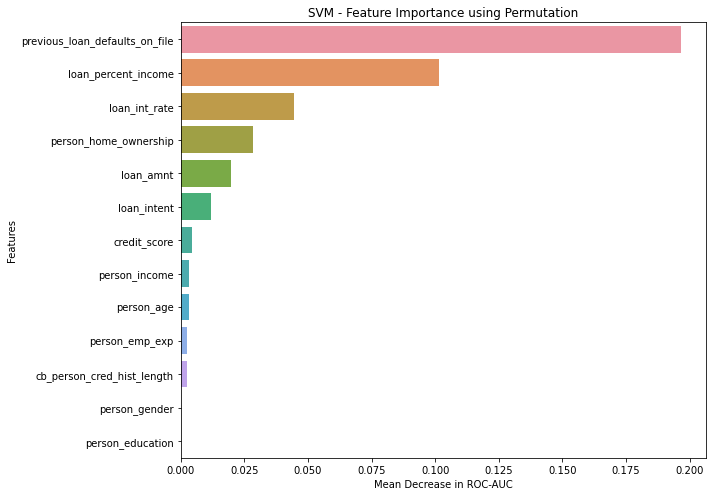

In [63]:
# Visualise SVM feature importance

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('SVM - Feature Importance using Permutation')
plt.xlabel('Mean Decrease in ROC-AUC')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [64]:
# Create final model comparison table

model_results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'SVM'
    ],

    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        knn_accuracy,
        nb_accuracy,
        svm_accuracy
    ],

    'Precision': [
        lr_precision,
        dt_precision,
        knn_precision,
        nb_precision,
        svm_precision
    ],

    'Recall': [
        lr_recall,
        dt_recall,
        knn_recall,
        nb_recall,
        svm_recall
    ],

    'F1 Score': [
        lr_f1,
        dt_f1,
        knn_f1,
        nb_f1,
        svm_f1
    ],

    'ROC-AUC': [
        lr_roc_auc,
        dt_roc_auc,
        knn_roc_auc,
        nb_roc_auc,
        svm_roc_auc
    ],

    'Training Time': [
        lr_training_time,
        dt_training_time,
        knn_training_time,
        nb_training_time,
        svm_training_time
    ]
})

display(model_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time
0,Logistic Regression,0.8949,0.7722,0.7475,0.7597,0.9523,1.1409
1,Decision Tree,0.8940,0.7519,0.7805,0.7659,0.8535,0.6304
2,KNN,0.8959,0.7974,0.7125,0.7526,0.9255,0.1428
3,Gaussian Naive Bayes,0.7327,0.4539,0.9980,0.6240,0.9360,0.1848
4,SVM,0.9165,0.8534,0.7540,0.8006,0.9630,51.1531


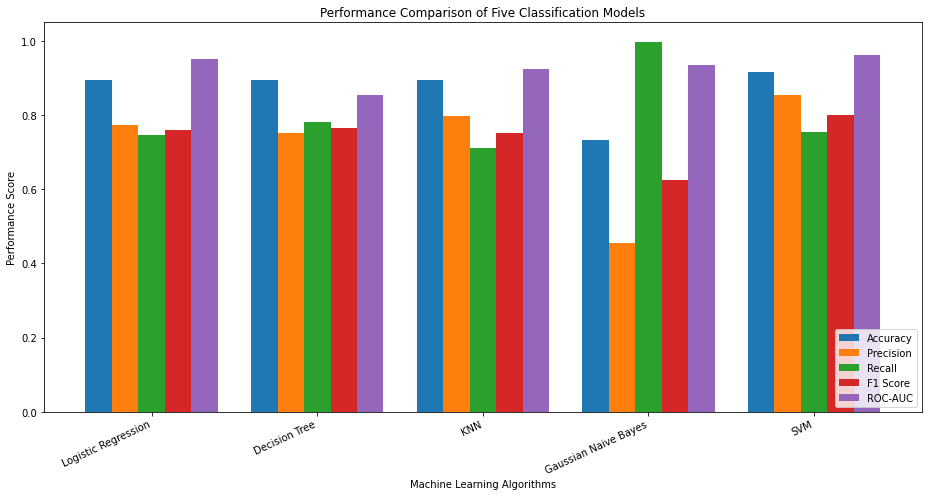

In [65]:
# Compare classification model performance

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

comparison_df = model_results.set_index('Model')[metrics]

comparison_df.plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8
)

plt.title('Performance Comparison of Five Classification Models')

plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Algorithms')

plt.ylim(0, 1.05)

plt.xticks(rotation=25, ha='right')

plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

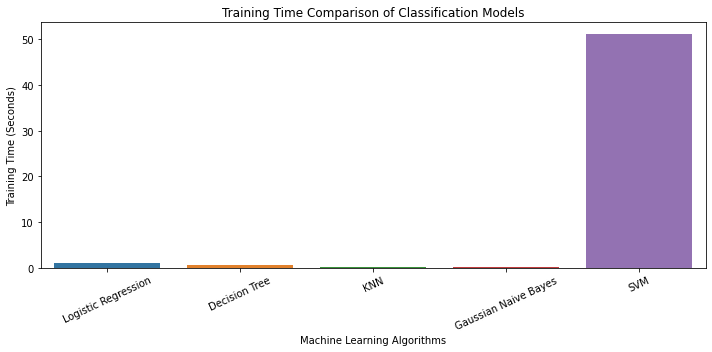

In [66]:
# Compare model training time

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x='Model',
    y='Training Time'
)

plt.title('Training Time Comparison of Classification Models')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Training Time (Seconds)')

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

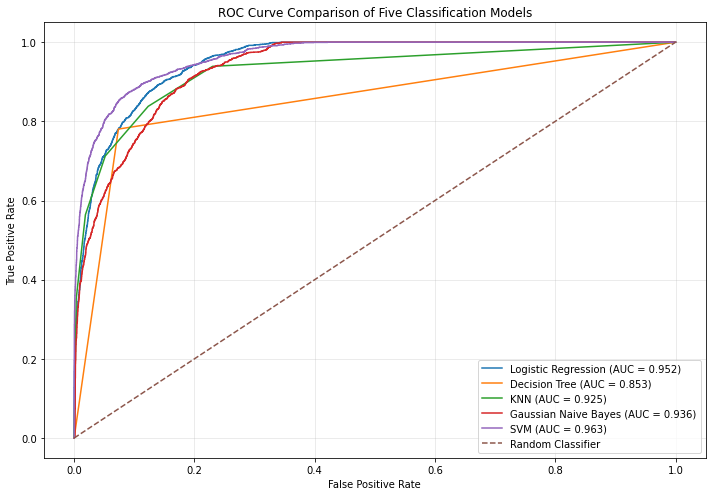

In [67]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Store all trained models
trained_models = {
    'Logistic Regression': lr_model,
    'Decision Tree': dt_model,
    'KNN': knn_model,
    'Gaussian Naive Bayes': nb_model,
    'SVM': svm_model
}

plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    if name == 'SVM':
        y_scores = model.decision_function(X_test)
    else:
        y_scores = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_scores)

    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc_value:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison of Five Classification Models')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [68]:
# Import cross-validation tools

from sklearn.model_selection import StratifiedKFold, cross_validate

print("Cross-validation tools imported successfully!")


Cross-validation tools imported successfully!


In [69]:
# Configure Stratified 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation configured successfully!")

print("Number of folds:", cv.get_n_splits())
print("Training dataset shape:", X_train.shape)
print("Target dataset shape:", y_train.shape)

Stratified 5-Fold Cross-Validation configured successfully!
Number of folds: 5
Training dataset shape: (35994, 13)
Target dataset shape: (35994,)


In [70]:
# Perform 5-Fold Cross-Validation for SVM

scoring_metrics = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

start_time = time.time()

svm_cv_results = cross_validate(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_metrics,
    n_jobs=-1,
    return_train_score=False
)

end_time = time.time()

svm_cv_time = end_time - start_time

print("SVM Cross-Validation Completed Successfully!")

print("Execution Time:", round(svm_cv_time, 2), "seconds")

SVM Cross-Validation Completed Successfully!
Execution Time: 63.0 seconds


In [71]:
# Calculate SVM Cross-Validation Performance

svm_cv_summary = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],

    'Mean Score': [
        svm_cv_results['test_accuracy'].mean(),
        svm_cv_results['test_precision'].mean(),
        svm_cv_results['test_recall'].mean(),
        svm_cv_results['test_f1'].mean(),
        svm_cv_results['test_roc_auc'].mean()
    ],

    'Standard Deviation': [
        svm_cv_results['test_accuracy'].std(),
        svm_cv_results['test_precision'].std(),
        svm_cv_results['test_recall'].std(),
        svm_cv_results['test_f1'].std(),
        svm_cv_results['test_roc_auc'].std()
    ]
})

print("SVM - 5 Fold Cross-Validation Results")
print("-------------------------------------")

display(svm_cv_summary.round(4))

SVM - 5 Fold Cross-Validation Results
-------------------------------------


,Metric,Mean Score,Standard Deviation
0,Accuracy,0.9156,0.0028
1,Precision,0.8497,0.0077
2,Recall,0.7535,0.0108
3,F1 Score,0.7986,0.0072
4,ROC-AUC,0.9622,0.0024


In [72]:
# Perform 5-Fold Cross-Validation for SVM
# Without Previous Loan Defaults Feature

start_time = time.time()

svm_reduced_cv_results = cross_validate(
    svm_reduced,
    X_train_reduced,
    y_train,
    cv=cv,
    scoring=scoring_metrics,
    n_jobs=-1,
    return_train_score=False
)

end_time = time.time()

svm_reduced_cv_time = end_time - start_time

print("SVM Cross-Validation Without Previous Defaults Completed!")

print("Execution Time:",
      round(svm_reduced_cv_time, 2), "seconds")

SVM Cross-Validation Without Previous Defaults Completed!
Execution Time: 97.74 seconds


In [73]:
# Compare SVM Cross-Validation Results

comparison_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],

    'SVM With All Features': [
        svm_cv_results['test_accuracy'].mean(),
        svm_cv_results['test_precision'].mean(),
        svm_cv_results['test_recall'].mean(),
        svm_cv_results['test_f1'].mean(),
        svm_cv_results['test_roc_auc'].mean()
    ],

    'SVM Without Previous Defaults': [
        svm_reduced_cv_results['test_accuracy'].mean(),
        svm_reduced_cv_results['test_precision'].mean(),
        svm_reduced_cv_results['test_recall'].mean(),
        svm_reduced_cv_results['test_f1'].mean(),
        svm_reduced_cv_results['test_roc_auc'].mean()
    ]
})

display(comparison_results.round(4))

,Metric,SVM With All Features,SVM Without Previous Defaults
0,Accuracy,0.9156,0.8856
1,Precision,0.8497,0.8775
2,Recall,0.7535,0.5642
3,F1 Score,0.7986,0.6868
4,ROC-AUC,0.9622,0.8777


In [74]:
# Import Matthews Correlation Coefficient

from sklearn.metrics import matthews_corrcoef

# Calculate MCC for all five models

mcc_results = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'SVM'
    ],

    'MCC Score': [
        matthews_corrcoef(y_test, y_pred_lr),
        matthews_corrcoef(y_test, y_pred_dt),
        matthews_corrcoef(y_test, y_pred_knn),
        matthews_corrcoef(y_test, y_pred_nb),
        matthews_corrcoef(y_test, y_pred_svm)
    ]
}

mcc_df = pd.DataFrame(mcc_results)

print("Matthews Correlation Coefficient")
display(mcc_df.round(4))

Matthews Correlation Coefficient


,Model,MCC Score
0,Logistic Regression,0.6926
1,Decision Tree,0.6977
2,KNN,0.6887
3,Gaussian Naive Bayes,0.5447
4,SVM,0.7504


In [75]:
# Create final model comparison table

final_comparison = model_results.merge(
    mcc_df,
    on='Model'
)

print("FINAL CLASSIFICATION MODEL COMPARISON")
print("-------------------------------------")

display(final_comparison.round(4))

FINAL CLASSIFICATION MODEL COMPARISON
-------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time,MCC Score
0,Logistic Regression,0.8949,0.7722,0.7475,0.7597,0.9523,1.1409,0.6926
1,Decision Tree,0.8940,0.7519,0.7805,0.7659,0.8535,0.6304,0.6977
2,KNN,0.8959,0.7974,0.7125,0.7526,0.9255,0.1428,0.6887
3,Gaussian Naive Bayes,0.7327,0.4539,0.9980,0.6240,0.9360,0.1848,0.5447
4,SVM,0.9165,0.8534,0.7540,0.8006,0.9630,51.1531,0.7504


In [76]:
import os
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Save all five trained pipelines
trained_models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "SVM": svm_model
}

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, os.path.join("models", filename))

print("All five models saved successfully!")

All five models saved successfully!


In [77]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nSaved model files:")

for file in os.listdir("models"):
    print("✓", file)

Current working directory:
C:\Python\Python39\Scripts\Loan_Approval_ML_Assignment

Saved model files:
✓ decision_tree.pkl
✓ gaussian_naive_bayes.pkl
✓ knn.pkl
✓ logistic_regression.pkl
✓ svm.pkl
